In [1]:
import sys
import numpy as np
from scipy.integrate import quad

import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.ticker import AutoMinorLocator
import scienceplots

from pathlib import Path

sys.path.append(str(Path("../python").resolve())) 

from utils import *

plt.style.use(['science'])

In [2]:
t_present = (2 + fv0) / (3*H_bar_0(fv0, H0))

print("Present time t0:", t_present)
z_of_t(t_present,fv0,H0)

Present time t0: 0.016485323383084574


2.220446049250313e-16

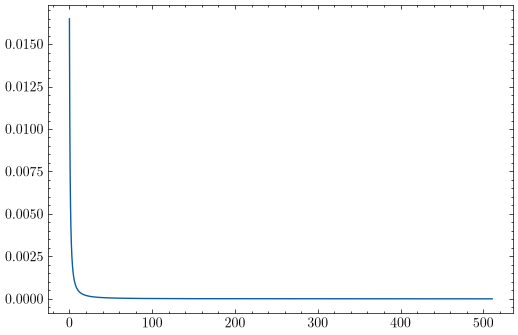

In [3]:
tt = np.geomspace(1e-4 * t_present, t_present, 1000)

fig, ax = plt.subplots(figsize=(6, 4))

ax.plot(z_of_t(tt, fv0, H0), tt)
# ax.vlines(t_present, 0, 120, color='r', linestyle='--', label='Present time')

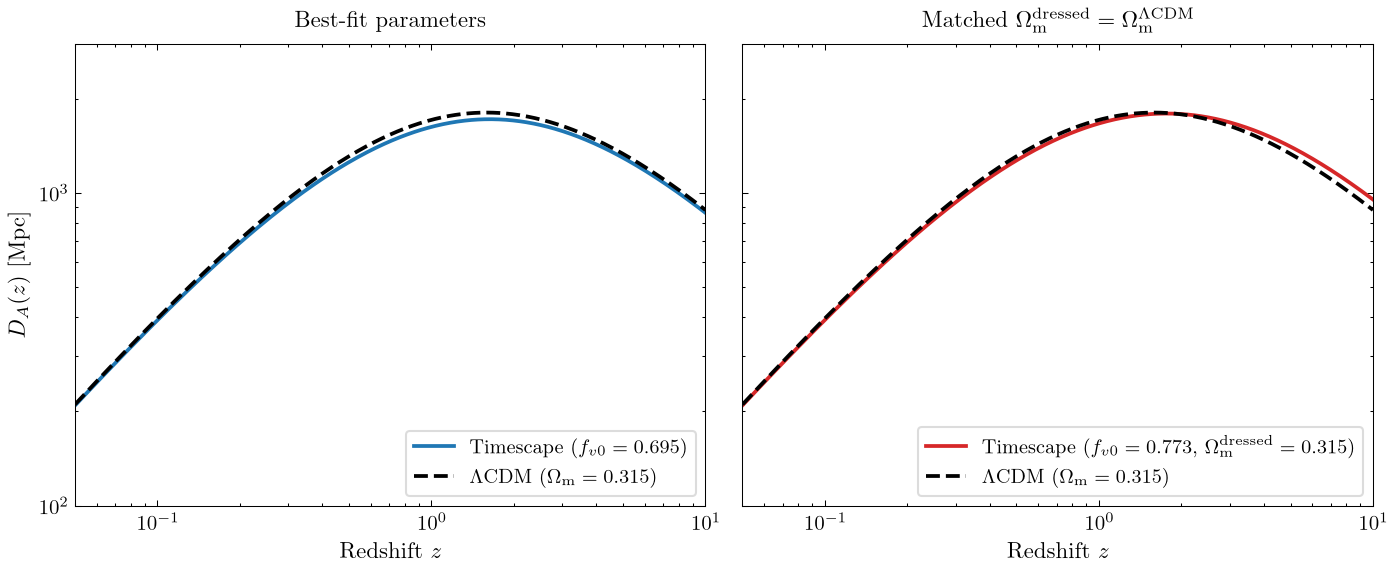

In [ ]:
# --- 1. Reference LCDM curve ---
zz_lcdm = np.geomspace(5e-2, 10, 500)
DA_lcdm_vals = DA_lcdm(zz_lcdm, H0, Omm)

# --- 2. Left panel data: Best-fit Timescape constraint (fv0 = 0.695) ---
fv0_best = 0.695
t0_best = (2 + fv0_best) / (3 * H_bar_0(fv0_best, H0))
tt_best = np.geomspace(1e-4 * t0_best, t0_best * 0.9999, 1000)
z_ts_best = z_of_t(tt_best, fv0_best, H0)
DA_ts_best = DA_timescape(tt_best, t0_best, fv0_best, H0)

# --- 3. Right panel data: Dressed Omega_m matched to LCDM Omega_m ---
fv0_matched = fv0_from_dressed_Omm(Omm)
t0_matched = (2 + fv0_matched) / (3 * H_bar_0(fv0_matched, H0))
tt_matched = np.geomspace(1e-4 * t0_matched, t0_matched * 0.9999, 1000)
z_ts_matched = z_of_t(tt_matched, fv0_matched, H0)
DA_ts_matched = DA_timescape(tt_matched, t0_matched, fv0_matched, H0)

# --- 4. Side-by-side Figure ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 4.0), sharey=True, dpi=150)

# Left panel: Best-fit parameters
ax1.loglog(z_ts_best, DA_ts_best, color='#1f77b4', lw=1.8,
           label=f'Timescape ($f_{{v0}}={fv0_best:.3f}$)')
ax1.loglog(zz_lcdm, DA_lcdm_vals, '--', color='black', lw=1.8,
           label=f'$\\Lambda$CDM ($\\Omega_{{\\rm m}}={Omm:.3f}$)')
ax1.set_title('Best-fit parameters', fontsize=11, pad=8)
ax1.set_xlabel('Redshift $z$', fontsize=11)
ax1.set_ylabel('$D_A(z)$ [Mpc]', fontsize=11)
ax1.set_xlim(5e-2, 10)
ax1.set_ylim(1e2, 3e3)
ax1.legend(frameon=True, facecolor='white', framealpha=0.9,
           edgecolor='0.85', fontsize=9.5, loc='lower right')

# Right panel: Matched dressed Omega_m = LCDM Omega_m
ax2.loglog(z_ts_matched, DA_ts_matched, color='#d62728', lw=1.8,
           label=f'Timescape ($f_{{v0}}={fv0_matched:.3f}$, $\\Omega_{{\\rm m}}^{{\\rm dressed}}={Omm:.3f}$)')
ax2.loglog(zz_lcdm, DA_lcdm_vals, '--', color='black', lw=1.8,
           label=f'$\\Lambda$CDM ($\\Omega_{{\\rm m}}={Omm:.3f}$)')
ax2.set_title(r'Matched $\Omega_{\rm m}^{\rm dressed} = \Omega_{\rm m}^{\Lambda\rm CDM}$', fontsize=11, pad=8)
ax2.set_xlabel('Redshift $z$', fontsize=11)
ax2.set_xlim(5e-2, 10)
ax2.legend(frameon=True, facecolor='white', framealpha=0.9,
           edgecolor='0.85', fontsize=9.5, loc='lower right')

for ax in (ax1, ax2):
    ax.tick_params(which='both', direction='in', top=True, right=True, labelsize=10)
    # ax.grid(True, which='major', ls=':', lw=0.6, alpha=0.45)

plt.tight_layout()
fig.savefig('../imgs/DA_comparison.pdf', bbox_inches='tight')
plt.show()

In [5]:
t_near = 0.9999 * t_present
print("Effective H0 at z->0:", c * z_of_t(t_near, fv0, H0) / DA_timescape(t_near, t_present, fv0, H0))

Effective H0 at z->0: 67.00762713613706


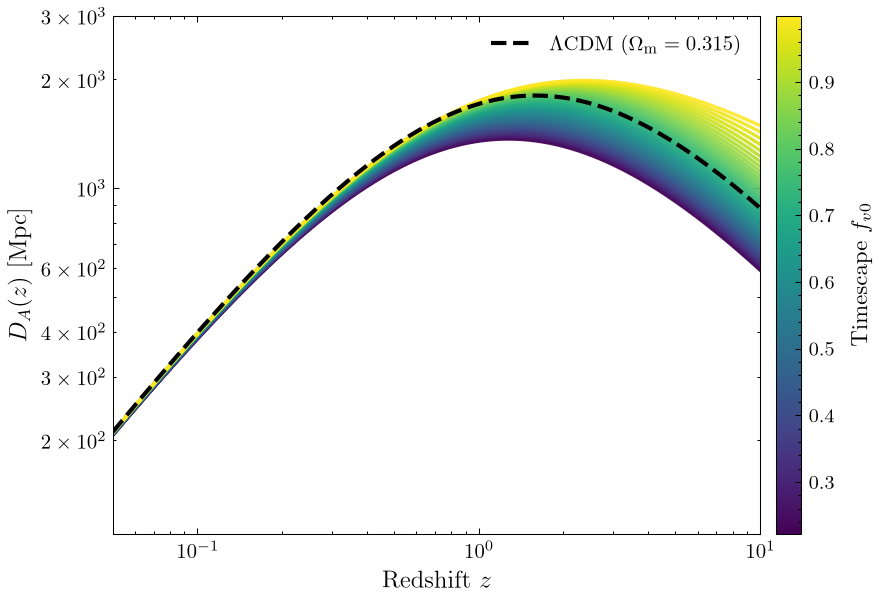

In [12]:
fv0_vals = np.linspace(fv0*0.32, 0.999, 50)

fig, ax1 = plt.subplots(figsize=(6.2, 4.2), dpi=150)

cmap = plt.cm.viridis
norm = mpl.colors.Normalize(vmin=fv0_vals.min(), vmax=fv0_vals.max())

for fv in fv0_vals:
    t_present = (2 + fv) / (3*H_bar_0(fv, H0))
    tt = np.geomspace(1e-4 * t_present, t_present, 1000)
    zz = z_of_t(tt, fv, H0)
    DA_ts = DA_timescape(tt, t_present, fv, H0)  # In Mpc

    ax1.loglog(zz, DA_ts, color=cmap(norm(fv)), lw=1.6, alpha=0.9)

ax1.loglog(zz_lcdm, DA_lcdm_vals, color='black', ls='--', lw=2.0, zorder=10,
         label=f'$\\Lambda$CDM ($\\Omega_{{\\rm m}}={Omm}$)')

# Colorbar for Timescape f_v0 values
sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax1, pad=0.02)
cbar.set_label(r'Timescape $f_{v0}$', fontsize=11, labelpad=8)
cbar.ax.tick_params(labelsize=9.5)

# Axes limits, labels, ticks, and grid
ax1.set_xlim(5e-2, 10)
ax1.set_ylim(1.1e2, 3e3)
ax1.set_xlabel('Redshift $z$', fontsize=12)
ax1.set_ylabel('$D_A(z)$ [Mpc]', fontsize=12)

ax1.legend()

plt.tight_layout()
fig.savefig('../imgs/DA_pars.pdf', bbox_inches='tight')
plt.show()


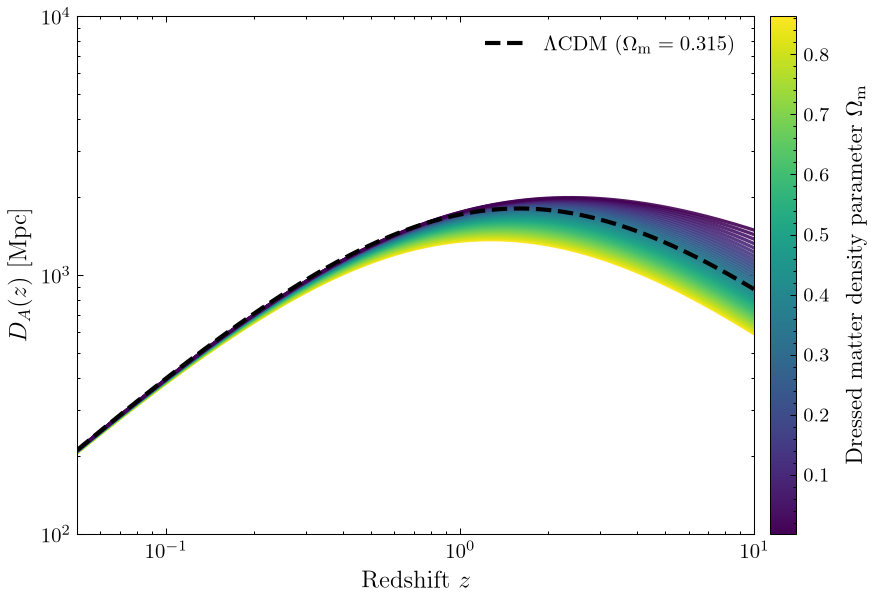

In [13]:
import matplotlib as mpl
from matplotlib.ticker import AutoMinorLocator
fv0 = 0.695



fv0_vals = np.linspace(fv0*0.32, 0.999, 50)
drsd_Omm_vals = dressed_Omm(fv0_vals)

fig, ax1 = plt.subplots(figsize=(6.2, 4.2), dpi=150)

cmap = plt.cm.viridis
norm = mpl.colors.Normalize(vmin=drsd_Omm_vals.min(), vmax=drsd_Omm_vals.max())

for fv in fv0_vals:
    t_present = (2 + fv) / (3*H_bar_0(fv, H0))
    tt = np.geomspace(1e-4 * t_present, t_present, 1000)
    zz = z_of_t(tt, fv, H0)
    DA_ts = DA_timescape(tt, t_present, fv, H0)  # In Mpc

    
    ax1.loglog(zz, DA_ts, color=cmap(norm(dressed_Omm(fv))), lw=1.6, alpha=0.9)

ax1.loglog(zz_lcdm, DA_lcdm_vals, color='black', ls='--', lw=2.0, zorder=10,
         label=f'$\\Lambda$CDM ($\\Omega_{{\\rm m}}={Omm}$)')

# Colorbar for Timescape f_v0 values
sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax1, pad=0.02)
cbar.set_label(r'Dressed matter density parameter $\Omega_{\rm m}$', fontsize=11, labelpad=8)
cbar.ax.tick_params(labelsize=9.5)

# Axes limits, labels, ticks, and grid
ax1.set_xlim(5e-2, 10)
ax1.set_ylim(1e2, 1e4)
ax1.set_xlabel('Redshift $z$', fontsize=12)
ax1.set_ylabel('$D_A(z)$ [Mpc]', fontsize=12)

ax1.legend()

plt.tight_layout()
fig.savefig('../imgs/DA_pars_omm.pdf', bbox_inches='tight')
plt.show()


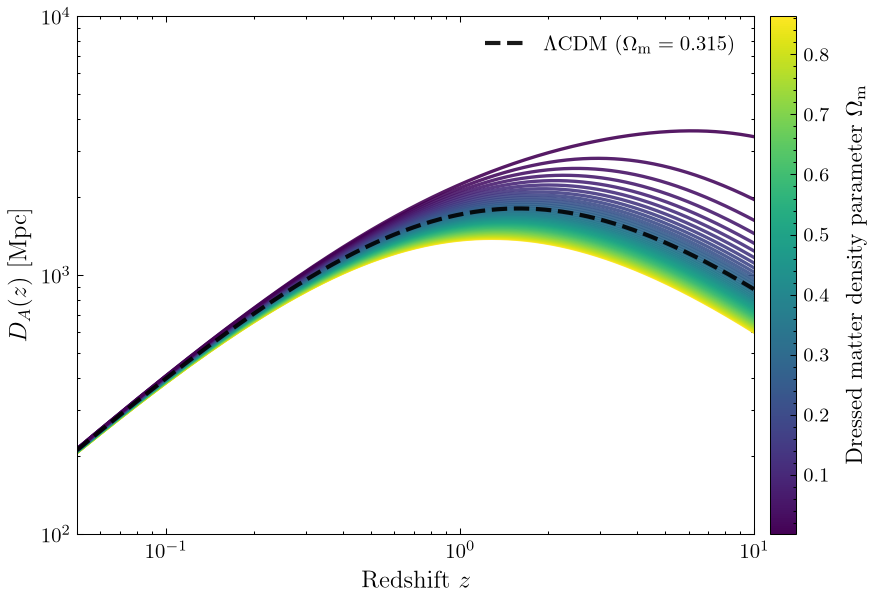

In [14]:
fv0_vals = np.linspace(fv0*0.32, 0.999, 50)
drsd_Omm_vals = dressed_Omm(fv0_vals)
zz = np.linspace(5e-2, 10, 1000)
fig, ax1 = plt.subplots(figsize=(6.2, 4.2), dpi=150)

cmap = plt.cm.viridis
norm = mpl.colors.Normalize(vmin=drsd_Omm_vals.min(), vmax=drsd_Omm_vals.max())

for fv in fv0_vals:
    DA_lcdm_vals = DA_lcdm(zz, H0, dressed_Omm(fv))  # In Mpc
    ax1.loglog(zz, DA_lcdm_vals, color=cmap(norm(dressed_Omm(fv))), lw=1.6, alpha=0.9)

DA_lcdm_val = DA_lcdm(zz, H0, Omm)
ax1.loglog(zz, DA_lcdm_val, '--',color='k', lw=2.0, alpha=0.9, label=f'$\\Lambda$CDM ($\\Omega_{{\\rm m}}={Omm}$)')

# Colorbar for Timescape f_v0 values
sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax1, pad=0.02)
cbar.set_label(r'Dressed matter density parameter $\Omega_{\rm m}$', fontsize=11, labelpad=8)
cbar.ax.tick_params(labelsize=9.5)

# Axes limits, labels, ticks, and grid
ax1.set_xlim(5e-2, 10)
ax1.set_ylim(1e2, 1e4)
ax1.set_xlabel('Redshift $z$', fontsize=12)
ax1.set_ylabel('$D_A(z)$ [Mpc]', fontsize=12)

ax1.legend()

plt.tight_layout()
fig.savefig('../imgs/DAlcdm_pars_omm.pdf', bbox_inches='tight')
plt.show()


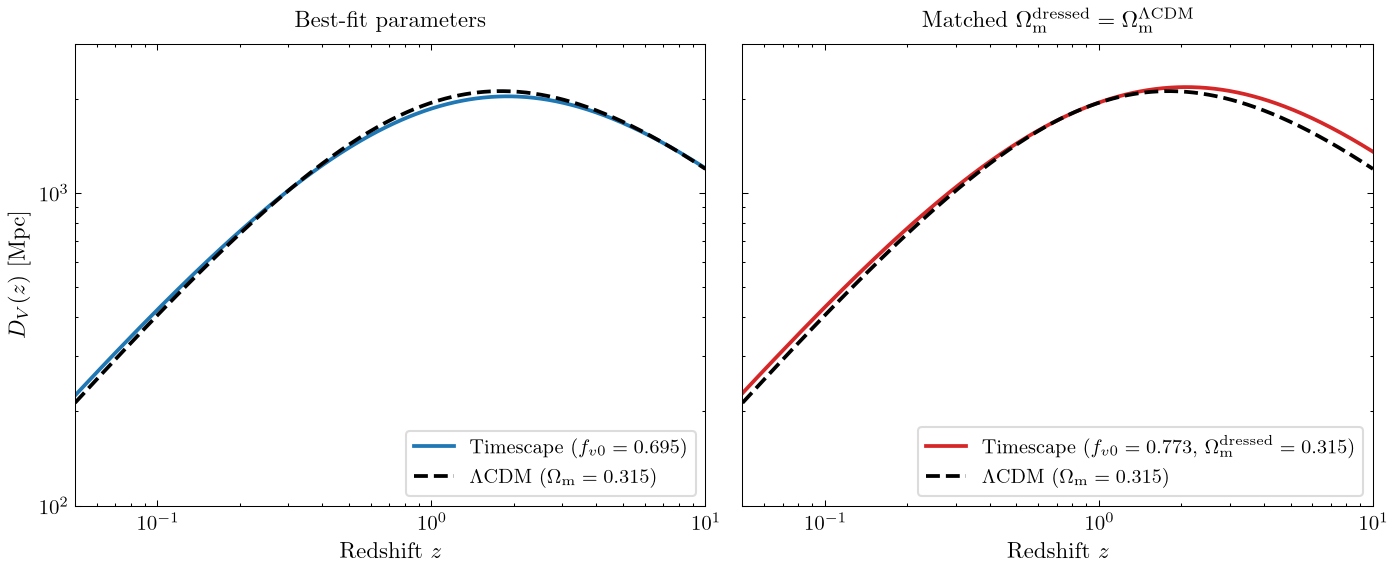

In [16]:
# --- 1. Reference LCDM curve ---
zz_lcdm = np.geomspace(5e-2, 10, 500)
DV_lcdm_vals = DV_lcdm(zz_lcdm, H0, Omm)

# --- 2. Left panel data: Best-fit Timescape constraint (fv0 = 0.695) ---
fv0_best = 0.695
t0_best = (2 + fv0_best) / (3 * H_bar_0(fv0_best, H0))
tt_best = np.geomspace(1e-4 * t0_best, t0_best * 0.9999, 1000)
z_ts_best = z_of_t(tt_best, fv0_best, H0)
DV_ts_best = DV_timescape(tt_best, t0_best, fv0_best, H0)

# --- 3. Right panel data: Dressed Omega_m matched to LCDM Omega_m ---
fv0_matched = fv0_from_dressed_Omm(Omm)
t0_matched = (2 + fv0_matched) / (3 * H_bar_0(fv0_matched, H0))
tt_matched = np.geomspace(1e-4 * t0_matched, t0_matched * 0.9999, 1000)
z_ts_matched = z_of_t(tt_matched, fv0_matched, H0)
DV_ts_matched = DV_timescape(tt_matched, t0_matched, fv0_matched, H0)

# --- 4. Side-by-side Figure ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 4.0), sharey=True, dpi=150)

# Left panel: Best-fit parameters
ax1.loglog(z_ts_best, DV_ts_best, color='#1f77b4', lw=1.8,
           label=f'Timescape ($f_{{v0}}={fv0_best:.3f}$)')
ax1.loglog(zz_lcdm, DV_lcdm_vals, '--', color='black', lw=1.8,
           label=f'$\\Lambda$CDM ($\\Omega_{{\\rm m}}={Omm:.3f}$)')
ax1.set_title('Best-fit parameters', fontsize=11, pad=8)
ax1.set_xlabel('Redshift $z$', fontsize=11)
ax1.set_ylabel('$D_V(z)$ [Mpc]', fontsize=11)
ax1.set_xlim(5e-2, 10)
ax1.set_ylim(1e2, 3e3)
ax1.legend(frameon=True, facecolor='white', framealpha=0.9,
           edgecolor='0.85', fontsize=9.5, loc='lower right')

# Right panel: Matched dressed Omega_m = LCDM Omega_m
ax2.loglog(z_ts_matched, DV_ts_matched, color='#d62728', lw=1.8,
           label=f'Timescape ($f_{{v0}}={fv0_matched:.3f}$, $\\Omega_{{\\rm m}}^{{\\rm dressed}}={Omm:.3f}$)')
ax2.loglog(zz_lcdm, DV_lcdm_vals, '--', color='black', lw=1.8,
           label=f'$\\Lambda$CDM ($\\Omega_{{\\rm m}}={Omm:.3f}$)')
ax2.set_title(r'Matched $\Omega_{\rm m}^{\rm dressed} = \Omega_{\rm m}^{\Lambda\rm CDM}$', fontsize=11, pad=8)
ax2.set_xlabel('Redshift $z$', fontsize=11)
ax2.set_xlim(5e-2, 10)
ax2.legend(frameon=True, facecolor='white', framealpha=0.9,
           edgecolor='0.85', fontsize=9.5, loc='lower right')

for ax in (ax1, ax2):
    ax.tick_params(which='both', direction='in', top=True, right=True, labelsize=10)
    # ax.grid(True, which='major', ls=':', lw=0.6, alpha=0.45)

plt.tight_layout()
fig.savefig('../imgs/DV_comparison.pdf', bbox_inches='tight')
plt.show()